In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [2]:
np.random.seed(42)

data = {
    'Property_ID': range(1, 101),

    'Location': np.random.choice(
        ['Chennai', 'Coimbatore', 'Erode', 'Salem'],
        100
    ),

    'Area_sqft': np.random.randint(600, 3000, 100),

    'Bedrooms': np.random.randint(1, 6, 100),

    'Bathrooms': np.random.randint(1, 4, 100),

    'Property_Type': np.random.choice(
        ['Apartment', 'Villa', 'Independent House'],
        100
    ),

    'Year_Built': np.random.randint(2000, 2026, 100)
}

df = pd.DataFrame(data)

location_rate = {
    'Chennai': 6500,
    'Coimbatore': 4500,
    'Erode': 3500,
    'Salem': 4000
}

df['Price'] = (
    df['Area_sqft'] *
    df['Location'].map(location_rate) *
    np.random.uniform(0.85, 1.15, 100)
).round(0)

print("Real Estate Dataset Created Successfully!")

df.head()

Real Estate Dataset Created Successfully!


,Property_ID,Location,Area_sqft,Bedrooms,Bathrooms,Property_Type,Year_Built,Price
0,1,Erode,1302,1,2,Independent House,2023,4547465.0
1,2,Salem,2179,4,1,Apartment,2004,7626372.0
2,3,Chennai,761,1,3,Villa,2012,4340609.0
3,4,Erode,801,1,3,Independent House,2003,2889658.0
4,5,Erode,2581,2,1,Villa,2015,9179038.0


In [3]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape:
(100, 8)

Column Names:
['Property_ID', 'Location', 'Area_sqft', 'Bedrooms', 'Bathrooms', 'Property_Type', 'Year_Built', 'Price']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Property_ID    100 non-null    int64  
 1   Location       100 non-null    object 
 2   Area_sqft      100 non-null    int64  
 3   Bedrooms       100 non-null    int64  
 4   Bathrooms      100 non-null    int64  
 5   Property_Type  100 non-null    object 
 6   Year_Built     100 non-null    int64  
 7   Price          100 non-null    float64
dtypes: float64(1), int64(5), object(2)
memory usage: 6.4+ KB

Statistical Summary:


,Property_ID,Area_sqft,Bedrooms,Bathrooms,Year_Built,Price
count,100.000000,100.000000,100.000000,100.000000,100.00000,1.000000e+02
mean,50.500000,1846.060000,2.680000,2.010000,2012.67000,8.405707e+06
std,29.011492,635.709813,1.354976,0.810225,7.67793,3.829881e+06
min,1.000000,664.000000,1.000000,1.000000,2000.00000,2.573652e+06
25%,25.750000,1349.500000,1.000000,1.000000,2006.00000,5.650692e+06
50%,50.500000,1878.500000,3.000000,2.000000,2012.00000,8.146640e+06
75%,75.250000,2352.500000,4.000000,3.000000,2018.25000,1.029752e+07
max,100.000000,2943.000000,5.000000,3.000000,2025.00000,2.149852e+07


In [4]:
df.loc[2, 'Price'] = np.nan
df.loc[5, 'Location'] = np.nan
df.loc[8, 'Area_sqft'] = np.nan
df.loc[12, 'Bedrooms'] = np.nan

df = pd.concat([df, df.iloc[[0, 1]]], ignore_index=True)

print("Missing Values and Duplicates Added!")

Missing Values and Duplicates Added!


In [5]:
print("Missing Values in Each Column:")

print(df.isnull().sum())

print("\nTotal Missing Values:")

print(df.isnull().sum().sum())

Missing Values in Each Column:
Property_ID      0
Location         1
Area_sqft        1
Bedrooms         1
Bathrooms        0
Property_Type    0
Year_Built       0
Price            1
dtype: int64

Total Missing Values:
4


In [6]:
print("Before Removing Duplicates:", df.shape)

df = df.drop_duplicates()

print("After Removing Duplicates:", df.shape)

Before Removing Duplicates: (102, 8)
After Removing Duplicates: (100, 8)


In [7]:
for col in df.select_dtypes(include=np.number).columns:

    df[col] = df[col].fillna(df[col].median())


for col in df.select_dtypes(include='object').columns:

    df[col] = df[col].fillna(df[col].mode()[0])


print("Missing Values Handled Successfully!")

print(df.isnull().sum())

Missing Values Handled Successfully!
Property_ID      0
Location         0
Area_sqft        0
Bedrooms         0
Bathrooms        0
Property_Type    0
Year_Built       0
Price            0
dtype: int64


In [10]:
print("Cleaned Dataset")

display(df.head(10))

print("\nTotal Records:", len(df))

print("Total Columns:", len(df.columns))

print("Duplicate Records:", df.duplicated().sum())

print("Missing Values:", df.isnull().sum().sum())

Cleaned Dataset


,Property_ID,Location,Area_sqft,Bedrooms,Bathrooms,Property_Type,Year_Built,Price
0,1,Erode,1302.0,1.0,2,Independent House,2023,4547465.0
1,2,Salem,2179.0,4.0,1,Apartment,2004,7626372.0
2,3,Chennai,761.0,1.0,3,Villa,2012,8147518.0
3,4,Erode,801.0,1.0,3,Independent House,2003,2889658.0
4,5,Erode,2581.0,2.0,1,Villa,2015,9179038.0
5,6,Salem,1595.0,4.0,1,Apartment,2023,5830161.0
6,7,Chennai,2917.0,4.0,3,Villa,2015,21498521.0
7,8,Chennai,1415.0,2.0,3,Villa,2022,9973666.0
8,9,Erode,1882.0,3.0,2,Villa,2001,3264315.0
9,10,Coimbatore,1875.0,1.0,3,Villa,2016,9528289.0



Total Records: 100
Total Columns: 8
Duplicate Records: 0
Missing Values: 0


In [11]:
print("Property Price Analysis")

print("\nAverage Price:")
print(df['Price'].mean())

print("\nMinimum Price:")
print(df['Price'].min())

print("\nMaximum Price:")
print(df['Price'].max())

print("\nAverage Property Area:")
print(df['Area_sqft'].mean())

Property Price Analysis

Average Price:
8443776.29

Minimum Price:
2573652.0

Maximum Price:
21498521.0

Average Property Area:
1854.33


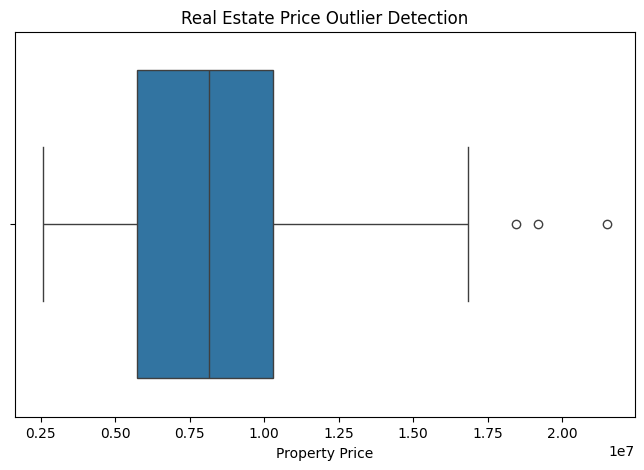

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Price'])

plt.title("Real Estate Price Outlier Detection")

plt.xlabel("Property Price")

plt.show()

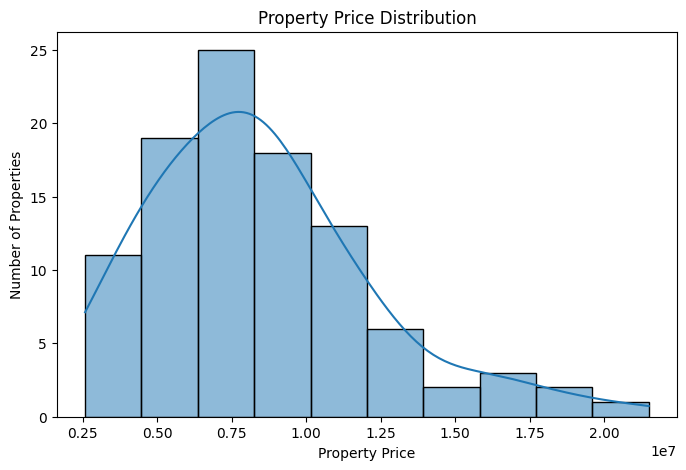

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='Price', kde=True)

plt.title("Property Price Distribution")

plt.xlabel("Property Price")

plt.ylabel("Number of Properties")

plt.show()

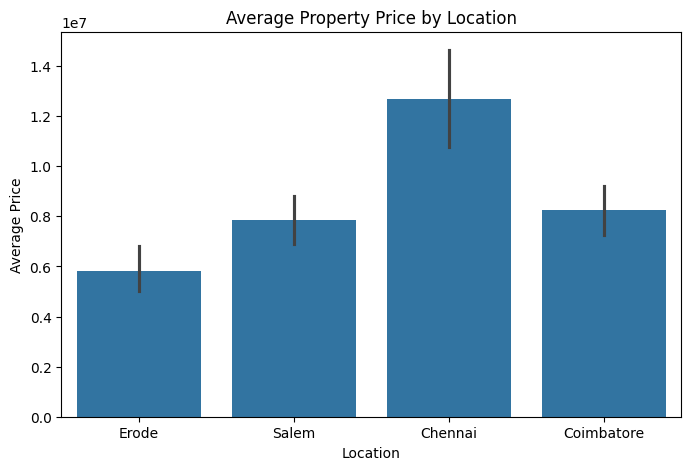

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Location',
    y='Price'
)

plt.title("Average Property Price by Location")

plt.xlabel("Location")

plt.ylabel("Average Price")

plt.show()

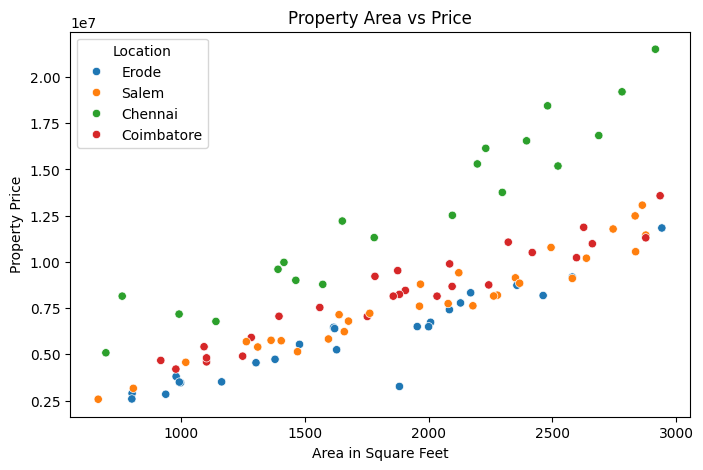

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Area_sqft',
    y='Price',
    hue='Location'
)

plt.title("Property Area vs Price")

plt.xlabel("Area in Square Feet")

plt.ylabel("Property Price")

plt.show()

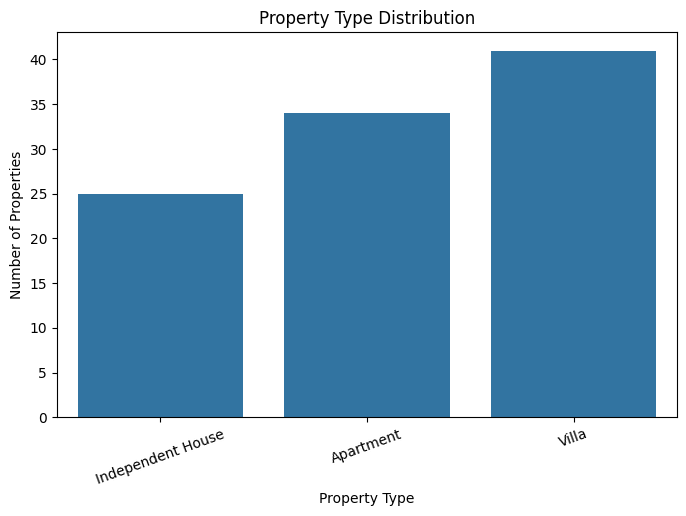

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Property_Type'
)

plt.title("Property Type Distribution")

plt.xlabel("Property Type")

plt.ylabel("Number of Properties")

plt.xticks(rotation=20)

plt.show()

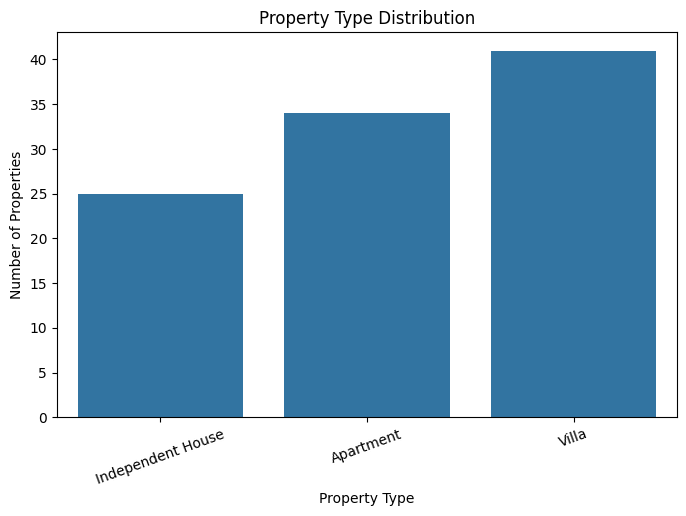

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Property_Type'
)

plt.title("Property Type Distribution")

plt.xlabel("Property Type")

plt.ylabel("Number of Properties")

plt.xticks(rotation=20)

plt.show()

In [18]:
print("Properties Available in Each Location:")

print(df['Location'].value_counts())

Properties Available in Each Location:
Location
Salem         30
Coimbatore    26
Erode         24
Chennai       20
Name: count, dtype: int64


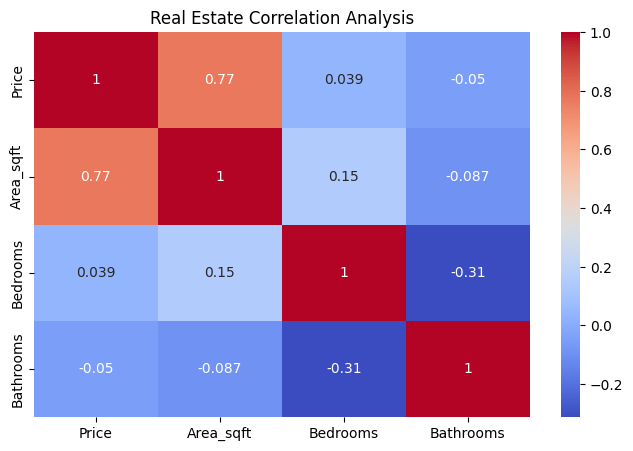

In [19]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df[['Price', 'Area_sqft', 'Bedrooms', 'Bathrooms']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Real Estate Correlation Analysis")

plt.show()

In [20]:
print("========== REAL ESTATE EDA REPORT ==========")

print("Total Properties:", len(df))

print("Total Locations:", df['Location'].nunique())

print("Average Property Price:", round(df['Price'].mean(), 2))

print("Highest Property Price:", df['Price'].max())

print("Lowest Property Price:", df['Price'].min())

print("Average Area:", round(df['Area_sqft'].mean(), 2))

print("\nLocation-wise Average Price:")

print(df.groupby('Location')['Price'].mean())

print("\nPROJECT ANALYSIS COMPLETED!")

========== REAL ESTATE EDA REPORT ==========
Total Properties: 100
Total Locations: 4
Average Property Price: 8443776.29
Highest Property Price: 21498521.0
Lowest Property Price: 2573652.0
Average Area: 1854.33

Location-wise Average Price:
Location
Chennai       1.267404e+07
Coimbatore    8.259128e+06
Erode         5.832361e+06
Salem         7.872764e+06
Name: Price, dtype: float64

PROJECT ANALYSIS COMPLETED!


In [21]:
df.to_csv('cleaned_real_estate.csv', index=False)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [22]:
from google.colab import files

files.download('cleaned_real_estate.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

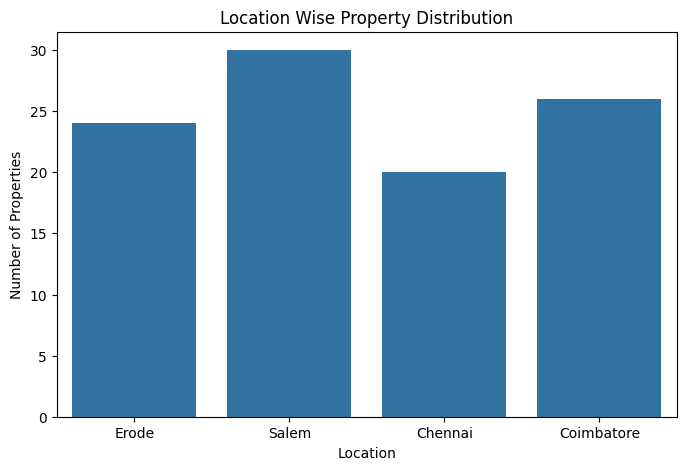

In [23]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Location'
)

plt.title("Location Wise Property Distribution")
plt.xlabel("Location")
plt.ylabel("Number of Properties")

plt.show()

In [24]:
df['Property_Size'] = pd.cut(
    df['Area_sqft'],
    bins=[0, 1000, 2000, float('inf')],
    labels=['Small', 'Medium', 'Large']
)

print("Property Size Distribution:")

print(df['Property_Size'].value_counts())

Property Size Distribution:
Property_Size
Large     44
Medium    43
Small     13
Name: count, dtype: int64


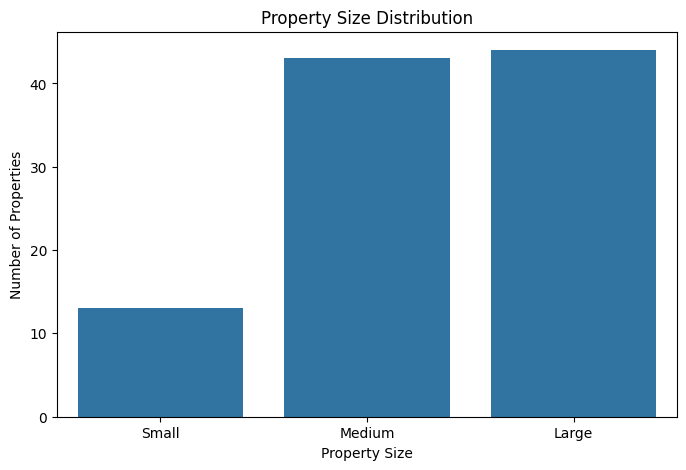

In [25]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Property_Size',
    order=['Small', 'Medium', 'Large']
)

plt.title("Property Size Distribution")
plt.xlabel("Property Size")
plt.ylabel("Number of Properties")

plt.show()

In [26]:
Q1 = df['Price'].quantile(0.25)

Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Price'] < lower_limit) |
    (df['Price'] > upper_limit)
]

print("Lower Limit:", lower_limit)

print("Upper Limit:", upper_limit)

print("Total Outliers:", len(outliers))

display(outliers)

Lower Limit: -1135926.0
Upper Limit: 17157582.0
Total Outliers: 3


,Property_ID,Location,Area_sqft,Bedrooms,Bathrooms,Property_Type,Year_Built,Price,Property_Size
6,7,Chennai,2917.0,4.0,3,Villa,2015,21498521.0,Large
38,39,Chennai,2782.0,5.0,1,Apartment,2007,19195562.0,Large
57,58,Chennai,2481.0,1.0,2,Apartment,2003,18438560.0,Large


In [27]:
df_analysis = df[
    (df['Price'] >= lower_limit) &
    (df['Price'] <= upper_limit)
].copy()

print("Original Records:", len(df))

print("Records After Outlier Filtering:",
      len(df_analysis))

Original Records: 100
Records After Outlier Filtering: 97


In [28]:
print("===== FINAL REAL ESTATE FINDINGS =====")

print("\n1. Total Properties:")
print(len(df))

print("\n2. Total Locations:")
print(df['Location'].nunique())

print("\n3. Average Property Price:")
print(round(df['Price'].mean(), 2))

print("\n4. Highest Property Price:")
print(df['Price'].max())

print("\n5. Lowest Property Price:")
print(df['Price'].min())

print("\n6. Average Property Area:")
print(round(df['Area_sqft'].mean(), 2))

print("\n7. Most Common Property Type:")
print(df['Property_Type'].mode()[0])

print("\n8. Location Wise Average Price:")
print(df.groupby('Location')['Price'].mean())

print("\n9. Total Outliers:")
print(len(outliers))

print("\n===== ANALYSIS COMPLETED =====")

===== FINAL REAL ESTATE FINDINGS =====

1. Total Properties:
100

2. Total Locations:
4

3. Average Property Price:
8443776.29

4. Highest Property Price:
21498521.0

5. Lowest Property Price:
2573652.0

6. Average Property Area:
1854.33

7. Most Common Property Type:
Villa

8. Location Wise Average Price:
Location
Chennai       1.267404e+07
Coimbatore    8.259128e+06
Erode         5.832361e+06
Salem         7.872764e+06
Name: Price, dtype: float64

9. Total Outliers:
3

===== ANALYSIS COMPLETED =====


In [29]:
print("===== FINAL DATA VERIFICATION =====")

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

print("Missing Values:",
      df.isnull().sum().sum())

print("Duplicate Records:",
      df.duplicated().sum())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFinal Dataset:")
display(df.head(10))

===== FINAL DATA VERIFICATION =====
Total Rows: 100
Total Columns: 9
Missing Values: 0
Duplicate Records: 0

Column Names:
['Property_ID', 'Location', 'Area_sqft', 'Bedrooms', 'Bathrooms', 'Property_Type', 'Year_Built', 'Price', 'Property_Size']

Final Dataset:


,Property_ID,Location,Area_sqft,Bedrooms,Bathrooms,Property_Type,Year_Built,Price,Property_Size
0,1,Erode,1302.0,1.0,2,Independent House,2023,4547465.0,Medium
1,2,Salem,2179.0,4.0,1,Apartment,2004,7626372.0,Large
2,3,Chennai,761.0,1.0,3,Villa,2012,8147518.0,Small
3,4,Erode,801.0,1.0,3,Independent House,2003,2889658.0,Small
4,5,Erode,2581.0,2.0,1,Villa,2015,9179038.0,Large
5,6,Salem,1595.0,4.0,1,Apartment,2023,5830161.0,Medium
6,7,Chennai,2917.0,4.0,3,Villa,2015,21498521.0,Large
7,8,Chennai,1415.0,2.0,3,Villa,2022,9973666.0,Medium
8,9,Erode,1882.0,3.0,2,Villa,2001,3264315.0,Medium
9,10,Coimbatore,1875.0,1.0,3,Villa,2016,9528289.0,Medium


In [31]:
import os

os.makedirs('Real_Estate_Project', exist_ok=True)

print("Project Folder Created Successfully!")

Project Folder Created Successfully!


In [32]:
df.to_csv(
    'Real_Estate_Project/cleaned_real_estate.csv',
    index=False
)

print("Cleaned Dataset Saved!")

Cleaned Dataset Saved!


In [33]:
outliers.to_csv(
    'Real_Estate_Project/outlier_report.csv',
    index=False
)

print("Outlier Report Saved!")

Outlier Report Saved!


In [34]:
with open(
    'Real_Estate_Project/final_findings.txt',
    'w'
) as file:

    file.write("REAL ESTATE EDA PROJECT\n")

    file.write("======================\n")

    file.write(f"Total Properties: {len(df)}\n")

    file.write(f"Total Locations: {df['Location'].nunique()}\n")

    file.write(f"Average Price: {df['Price'].mean():.2f}\n")

    file.write(f"Highest Price: {df['Price'].max()}\n")

    file.write(f"Lowest Price: {df['Price'].min()}\n")

    file.write(f"Average Area: {df['Area_sqft'].mean():.2f}\n")

    file.write(f"Total Outliers: {len(outliers)}\n")

print("Final Findings Saved!")

Final Findings Saved!


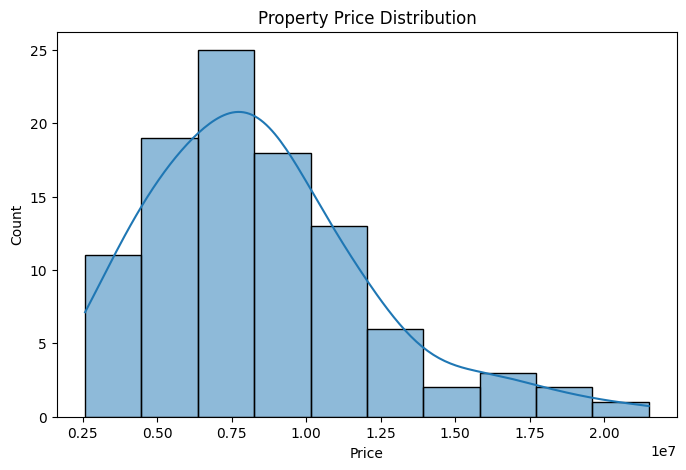

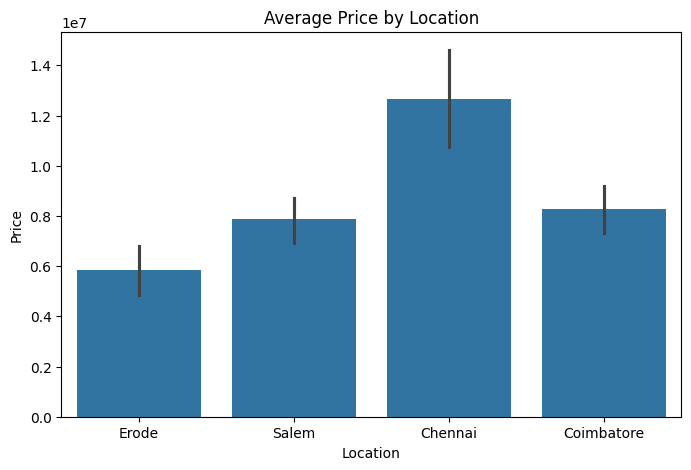

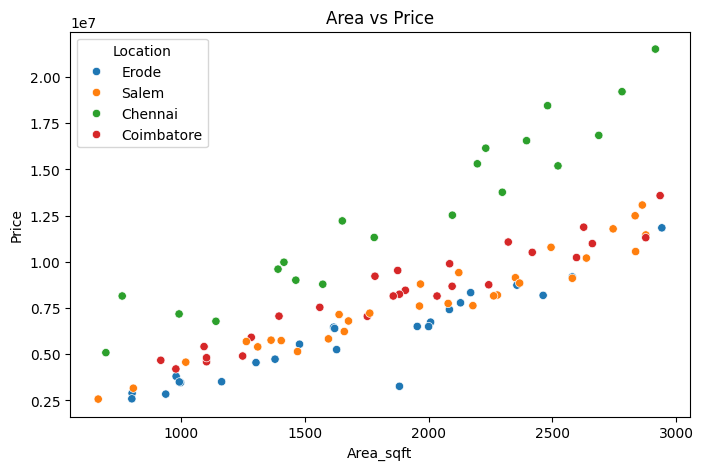

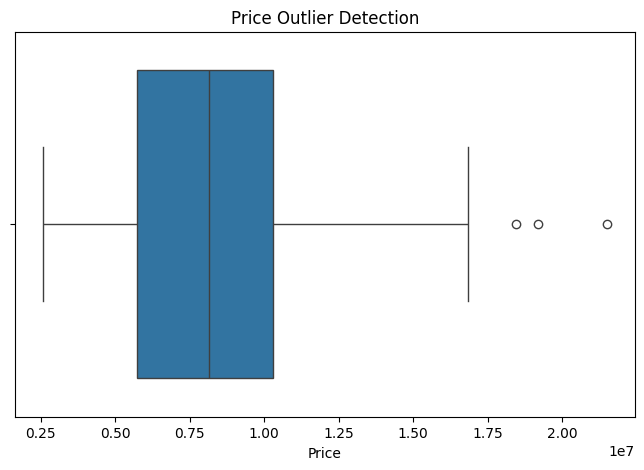

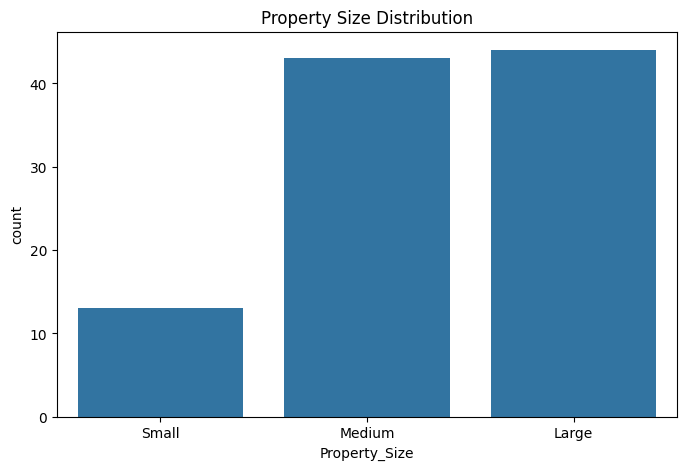

All Graphs Saved Successfully!


In [35]:
folder = 'Real_Estate_Project'

# 1. Price Distribution
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='Price', kde=True)
plt.title("Property Price Distribution")
plt.savefig(f'{folder}/price_distribution.png')
plt.show()

# 2. Location-wise Price
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='Location', y='Price')
plt.title("Average Price by Location")
plt.savefig(f'{folder}/location_price.png')
plt.show()

# 3. Area vs Price
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='Area_sqft', y='Price', hue='Location')
plt.title("Area vs Price")
plt.savefig(f'{folder}/area_vs_price.png')
plt.show()

# 4. Outlier Boxplot
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Price'])
plt.title("Price Outlier Detection")
plt.savefig(f'{folder}/outlier_boxplot.png')
plt.show()

# 5. Property Size
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Property_Size')
plt.title("Property Size Distribution")
plt.savefig(f'{folder}/property_size.png')
plt.show()

print("All Graphs Saved Successfully!")

In [36]:
import shutil

shutil.make_archive(
    'Real_Estate_EDA_Final',
    'zip',
    'Real_Estate_Project'
)

print("Final Project ZIP Created Successfully!")

Final Project ZIP Created Successfully!


In [37]:
from google.colab import files

files.download('Real_Estate_EDA_Final.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
from google.colab import files

files.download('Real_Estate_Project/cleaned_real_estate.csv')

files.download('Real_Estate_Project/outlier_report.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>